# 03. rrBLUP со случайным эффектом хозяйства


In [1]:
knitr::opts_chunk$set(
  echo = TRUE,
  message = FALSE,
  warning = FALSE,
  fig.width = 9,
  fig.height = 5
)


In [2]:
fix_categorical_effects = c('event_season', 'event_year')
fix_numerical_effects = c('dam_age', 'okot_massa', 'okot_number')
random_categorical_effects = c('animal', 'economy')
is_random = TRUE
diagonal_coefficient = 0.1


---
title: "03. rrBLUP со случайным эффектом хозяйства"
date: "`Sys.Date()`"
output:
  html_document:
    toc: true
    toc_depth: 3
    toc_float:
      collapsed: false
    theme: flatly
    highlight: tango
    df_print: paged
---


# О документе

Отчёт расширяет ssGBLUP: кроме животного в модель входит случайный эффект хозяйства (`economy`).

| | |
|---|---|
| **Данные** | `data/pedigree.csv`, `data/phenotypes.csv`, `data/genotypes.csv` |
| **Цель** | Склеить Z животного и Z хозяйства, собрать блочную K |
| **Результат** | EBV животных при учёте фона фермы |


In [3]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



# Вступление

Оценка племенной ценности методом BLUP (Best Linear Unbiased Prediction) является стандартом в генетике животных. Несмотря на широкое распространение специализированного програмного обеспечения, такого как семейство программ BLUPF90, в некоторых случаях может быть целесообразно реализовать расчёт вручную с помощью языка R. Это позволяет получить полный контроль над моделью, гибко адаптировать структуру данных, визуализировать промежуточные шаги и глубже понять математическую сущность модели.

Преимущества расчёта в среде R по сравнению с расчётом с помощью программы BLUPF90:

- Гибкость в модели. Возможность свободно варьировать структуру фиксированных и случаёных эффектов;

- Прозрачность алгоритма. Все необходимые матрицы создаются вручную. Мы видим, что происходит;

- Визуализация и диагностика. Можно сделать любую визуализацию на каждом этапе;

- Удобная отладка. При ошибке можно локализовать этап, где возникла проблема;

- Возможность включения новых алгоритмов. Можно добавить любой алгоритм, который повысит точность полученной оценки

Здесь представлен пошаговый расчёт BLUP в среде R, а сама модель построена как с учётом фиксированных, так и случайных эффектов

# 1. Загрузка данных

В первую очередь необходимо загрузить необходимые нам данные: 

- Данные родословной;

- Фенотипические данные;

- Данные по SNP-маркерам у генотипированных животных. 

Это обязательные данные для расчёта качественной оценки. Кроме того, нам будет необходим список всех животных, которые каким бы то ни было образом присутствуют в наших данных: это животные, по которым у нас есть фенотипические данные, генетические данные и сведения в родословной - как самого животного, так и его родителей. Согласно этому списку каждому животному будет присвоен номер.

Таблицы читаются из CSV, заранее сохранённых скриптом `tools/generate_data.R`.


In [4]:
phenotypes <- read.csv('data/phenotypes.csv') %>%
  dplyr::select(animal, okot_massa, okot_number, dam_age, event_season, event_year, economy, trait)
genotypes <- read.csv('data/genotypes.csv', colClasses = c(nom_osn = 'character', gen = 'character'))
pedigree <- read.csv('data/pedigree.csv')


Теперь, когда у нас есть все необходимые нам данные, мы можем приступать к их преобразованию для дальнейшей работы с ними.

# 2. Преобразование загруженных данных
Преобразование данных является неотъемлемой частью работы. Нам их необходимо преобразовать так, чтобы в дальнейшем их использовать для подачи в матрицы. С помощью этих матриц мы и будем рассчитывать оценки племенной ценности

## 2.1. Синхронизация родословной, данных генетики и фенотипов
В первую очередь, нам важно синхронизировать наши данные по родословной и генетики с данными фенотипов. Т.е. в этих двух датасетах оставить только тех животных, которые присутствуют в фенотипических данных. 

Затем нужно синхронизировать данные фенотипов. Это удаление пропущенных значений в любой из колонок - пропущенные значения отрицательно влияют на точность оценок. Затем - это синхронизация данных фенотипов с данными родословной. То есть в фенотипических данных присутсвуют только те животные, которые есть в родословной


In [5]:
pedigree <- pedigree %>%
  filter((animal %in% phenotypes$animal) | (dam %in% phenotypes$animal) | (sire %in% phenotypes$animal))
phenotypes <- phenotypes %>%
  drop_na() %>%
  filter(animal %in% pedigree$animal)
genotypes <- genotypes %>%
  filter(nom_osn %in% phenotypes$animal)
common_levels <- levels(as.factor(unique(c(phenotypes$animal, genotypes$nom_osn, pedigree$animal, pedigree$dam, pedigree$sire))))


In [6]:
print(knitr::kable(head(pedigree, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))
print(knitr::kable(head(genotypes %>% mutate(gen = str_trunc(gen, width = 25)), 5), booktabs=TRUE, caption='Данные генетики (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      1|    0|   0|
|      2|    0|   0|
|      3|    0|   0|
|      4|    0|   0|
|      5|    0|   0|




Table: Данные фенотипов (фрагмент)

| animal| okot_massa| okot_number|    dam_age|event_season | event_year|economy |      trait|
|------:|----------:|-----------:|----------:|:------------|----------:|:-------|----------:|
|      1|  0.0908113|   0.6679681| -0.5293859|summer       |       2022|farm4   |  0.8189411|
|      2|  0.2626232|  -0.0131677| -0.4707870|spring       |       2023|farm4   |  3.4704416|
|      3|  0.0693349|   0.7760470| -1.5459369|spring       |       2023|farm2   | -0.9278001|
|      4| -0.5286438|  -2.0107353| -0.0405267|autumn       |       2024|farm2   | -0.2795238|
|      5| -0.1302022|  -1.1281805|  0.8903563|spring       |       2022|farm2   | -0.4406823|




Table: Данные генетики (фрагмент)

|nom_osn |gen                       |
|:-------|:-------------------------|
|121     |1011011010010201101001... |
|122     |2112110001111200010010... |
|123     |1110000001121101101000... |
|124     |1001221120111201000000... |
|125     |0000101100010011000010... |


## 2.2. Преобразование родословной, генетики и фенотипов
На этом этапе мы заменяем ID животного, которое было у нас изначально из данных на номер, который мы получили согласно полному списку животных. С номером будет намного проще и удобнее строить матрицы, чем с использованием ID. 

Также мы всем колонкам присваиваем определённые типы: 

- колонки с номерами животных получают тип **integer**; 

- колонки с нумерованными эффектами получают тип **numeric**; 

- колонки с категориальными эффектами получают тип **factor**. 

Такая чёткая градация необходима для дальнейшего расчёта оценок.


In [7]:
pedigree_bl <- pedigree %>%
  mutate(across(c(animal, dam, sire), ~as.integer(factor(., levels = common_levels))))
genotypes_bl <- genotypes %>%
  mutate(nom_osn = as.integer(factor(nom_osn, levels=common_levels)))
phenotypes_bl <- phenotypes %>%
  mutate(animal = as.integer(factor(animal, levels=common_levels))) %>%
  mutate(across(all_of(fix_categorical_effects), ~factor(.x))) %>%
  mutate(across(all_of(fix_numerical_effects), ~as.numeric(.x))) %>%
  mutate(across(all_of(random_categorical_effects), ~factor(.x)))


In [8]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))
print(knitr::kable(head(genotypes_bl %>% mutate(gen = str_trunc(gen, width = 25)), 5), booktabs=TRUE, caption='Данные генетики (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      2|    1|   1|
|    113|    1|   1|
|    125|    1|   1|
|    136|    1|   1|
|    147|    1|   1|




Table: Данные фенотипов (фрагмент)

|animal | okot_massa| okot_number|    dam_age|event_season |event_year |economy |      trait|
|:------|----------:|-----------:|----------:|:------------|:----------|:-------|----------:|
|2      |  0.0908113|   0.6679681| -0.5293859|summer       |2022       |farm4   |  0.8189411|
|113    |  0.2626232|  -0.0131677| -0.4707870|spring       |2023       |farm4   |  3.4704416|
|125    |  0.0693349|   0.7760470| -1.5459369|spring       |2023       |farm2   | -0.9278001|
|136    | -0.5286438|  -2.0107353| -0.0405267|autumn       |2024       |farm2   | -0.2795238|
|147    | -0.1302022|  -1.1281805|  0.8903563|spring       |2022       |farm2   | -0.4406823|




Table: Данные генетики (фрагмент)

| nom_osn|gen                       |
|-------:|:-------------------------|
|      27|1011011010010201101001... |
|      28|2112110001111200010010... |
|      29|1110000001121101101000... |
|      30|1001221120111201000000... |
|      31|0000101100010011000010... |


## 2.3. Cинхронизация данных родословной
Здесь наша родословная нуждается в специальном преобразовании, ей необходимо присвоить определённый порядок, чтобы вначале было показано животное в столбце "animal" и только потом это животное появлялось в столбцах предков - "dam" и "sire". Такое преобразование будет сделано с помощью специальной функции editPed библиотеки "pedigreeTools".


In [9]:
pedigree_bl <- editPed(label=pedigree_bl$animal, dam = pedigree_bl$dam, sire = pedigree_bl$sire)[c('label', 'sire', 'dam')]
pedigree_bl <- pedigree_bl %>%
  filter(label %in% phenotypes_bl$animal)


Далее пропущенные значения у предков будут заменены на 0. Наконец, индексы в данных по родословной мы поставим сходими с номерами животных (колонка "label" в родословной).


In [10]:
pedigree_bl$sire[!(pedigree_bl$sire %in% pedigree_bl$label)] <- 0
pedigree_bl$dam[!(pedigree_bl$dam %in% pedigree_bl$label)] <- 0
rownames(pedigree_bl) <- pedigree_bl$label


In [11]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))
print(knitr::kable(head(genotypes_bl %>% mutate(gen = str_trunc(gen, width = 25)), 5), booktabs=TRUE, caption='Данные генетики (фрагмент)'))




Table: Данные родословной (фрагмент)

|    |label |sire |dam |
|:---|:-----|:----|:---|
|2   |2     |0    |0   |
|113 |113   |0    |0   |
|125 |125   |0    |0   |
|136 |136   |0    |0   |
|147 |147   |0    |0   |




Table: Данные фенотипов (фрагмент)

|animal | okot_massa| okot_number|    dam_age|event_season |event_year |economy |      trait|
|:------|----------:|-----------:|----------:|:------------|:----------|:-------|----------:|
|2      |  0.0908113|   0.6679681| -0.5293859|summer       |2022       |farm4   |  0.8189411|
|113    |  0.2626232|  -0.0131677| -0.4707870|spring       |2023       |farm4   |  3.4704416|
|125    |  0.0693349|   0.7760470| -1.5459369|spring       |2023       |farm2   | -0.9278001|
|136    | -0.5286438|  -2.0107353| -0.0405267|autumn       |2024       |farm2   | -0.2795238|
|147    | -0.1302022|  -1.1281805|  0.8903563|spring       |2022       |farm2   | -0.4406823|




Table: Данные генетики (фрагмент)

| nom_osn|gen                       |
|-------:|:-------------------------|
|      27|1011011010010201101001... |
|      28|2112110001111200010010... |
|      29|1110000001121101101000... |
|      30|1001221120111201000000... |
|      31|0000101100010011000010... |


После этого все необходимые преобразования данных выполнены. Моржно приступать непосредственно к построению матриц для расчёта оценки племенной ценности.

# 3. Постоение матриц

Матрицы считаются основным фундаментом расчёта оценок племенной ценности. От их правильного построения зависит как сама оценка, её возможная стандартная ошибка и точность.

## 3.1. Построение A матрицы родословной

Мы начнём с построения матрицы родословной. Она называется *A-матрицей*. Это матрица родственных коэффициентов, построенная по родословной. Она показывает отношения между всеми парами животных - насколько они похожи по информации родословной. Размер матрицы - *nrow(pedigree) x nrow(pedigree)*
Как рассчитываются коэффициенты внутри матрицы? 

- Диагональный коэффициент = 1 + инбридинг. 

- Остальные коэффициенты: 0.5 - родитель-потомок, 0.25 - родитель родителя - внук ...


In [12]:
A <- Amatrix(pedigree_bl, ploidy = 2)
rownames(A) <- as.numeric(rownames(A))


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 5e-05  minutes 


In [13]:
print(knitr::kable(A[1:5, 1:5], booktabs=TRUE, caption='Матрица А (фрагмент)'))




Table: Матрица А (фрагмент)

|    |  2| 113| 125| 136| 147|
|:---|--:|---:|---:|---:|---:|
|2   |  1|   0|   0|   0|   0|
|113 |  0|   1|   0|   0|   0|
|125 |  0|   0|   1|   0|   0|
|136 |  0|   0|   0|   1|   0|
|147 |  0|   0|   0|   0|   1|


Также мы рассчитаем обратную матрицу A<sup>-1</sup>. Она отражает влияние родителей на потомка. Такая матрица состоит из следующих компонентов. 

- Диагональный коэффициент: если оба родителя неизвестны - 1, если один родитель известен - тогда ~ 1.33, если оба родители известны - 2;

- Остальные коэффициенты: если присутствует влияние родителей - отрицательные значения, если нет влияния родителей - 0;

При расчёте обратной матрицы важно провести регуляризацию!


In [14]:
A_inv <- solve(A + diag(1e-6, nrow(A)))


In [15]:
print(knitr::kable(A_inv[1:5, 1:5], booktabs=TRUE, caption='Обратная матрица А (фрагмент)'))




Table: Обратная матрица А (фрагмент)

|    |       2|     113|      125|      136|      147|
|:---|-------:|-------:|--------:|--------:|--------:|
|2   | 2.49999| 0.00000| 0.000000| 0.000000| 0.000000|
|113 | 0.00000| 3.51611| 0.000000| 0.000000| 0.000000|
|125 | 0.00000| 0.00000| 3.499982| 0.000000| 0.000000|
|136 | 0.00000| 0.00000| 0.000000| 1.499996| 0.000000|
|147 | 0.00000| 0.00000| 0.000000| 0.000000| 3.499982|


Теперь мы должны синхронизировать наши данные по фенотипам с данными в матрице A, включая порядок номеров животных


In [16]:
phenotypes_bl <- phenotypes_bl[phenotypes_bl$animal %in% as.numeric(rownames(A)), ]
phenotypes_bl <- phenotypes_bl[match(as.numeric(rownames(A)), phenotypes_bl$animal), ]


In [17]:
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))




Table: Данные фенотипов (фрагмент)

|animal | okot_massa| okot_number|    dam_age|event_season |event_year |economy |      trait|
|:------|----------:|-----------:|----------:|:------------|:----------|:-------|----------:|
|2      |  0.0908113|   0.6679681| -0.5293859|summer       |2022       |farm4   |  0.8189411|
|113    |  0.2626232|  -0.0131677| -0.4707870|spring       |2023       |farm4   |  3.4704416|
|125    |  0.0693349|   0.7760470| -1.5459369|spring       |2023       |farm2   | -0.9278001|
|136    | -0.5286438|  -2.0107353| -0.0405267|autumn       |2024       |farm2   | -0.2795238|
|147    | -0.1302022|  -1.1281805|  0.8903563|spring       |2022       |farm2   | -0.4406823|


In [18]:
#проверка
all(phenotypes_bl$animal == rownames(A))


[1] TRUE


## 3.2. Построение X матрицы фиксированных эффектов

Следующую матрицу, которую мы будем строить, будет матрица фиксированных эффектов. Эта матрица также будет подаваться для расчёта оценки племенной ценности. Хочу ещё раз указать на важность присвоения каждой колонке определённого типа (*пункт 2.2*). Именно от этого действия будет зависить построение матрицы X.

Матрица X похожа на матрицу фенотипов с некоторыми особенностями: 

- Нет данных по трейту; 

- Данные по присвоенному номеру животного присутствует только в индексах; 

- Нумерованные эффекты автоматически отражены без изменений; 

- Категориальные эффекты автоматически отражены по принципу "*OneHotEncoding*"


In [19]:
X <- model.matrix(~ dam_age + okot_massa + okot_number + event_season + event_year, data=phenotypes_bl)  


In [20]:
print(knitr::kable(X[1:5, 1:5], booktabs=TRUE, caption='Матрица X (фрагмент)'))




Table: Матрица X (фрагмент)

| (Intercept)|    dam_age| okot_massa| okot_number| event_seasonspring|
|-----------:|----------:|----------:|-----------:|------------------:|
|           1| -0.5293859|  0.0908113|   0.6679681|                  0|
|           1| -0.4707870|  0.2626232|  -0.0131677|                  1|
|           1| -1.5459369|  0.0693349|   0.7760470|                  1|
|           1| -0.0405267| -0.5286438|  -2.0107353|                  0|
|           1|  0.8903563| -0.1302022|  -1.1281805|                  1|


Так мы закончили построение матрицы эффектов. Здесь важнен тот факт, что для точности оценки нам необходимо как можно больше эффектов как нумерованных, так и категориальных.

Проверяем линейную зависимость в матрице фиксированных эффектов


In [21]:
# проверка
cat('Rank X:', qr(X)$rank, 'of', ncol(X))


Rank X: 9 of 9


## 3.3. Построение матриц генетики M и G
Затем мы строим матрицы генотипов, и начнём мы с матрицы генетики M.
М - это матрица генотипов, где строки - это индивиды животных, а столбцы - генетические маркеры (SNP). Элементы - это кодировка самих аллелей (0, 1, 2, 5). Следвательно, размеры матрицы M составляют число животныx * число SNP-маркеров. Именно с M матрицей мы можем работать: заниматься её обработкой, строить различные DL или ML модели. Именно 
на основе M матрицы мы строим матрицу G, которя затем подаётся в расчёт оценки племенной ценности.


In [22]:
M <- t(sapply(genotypes_bl$gen, function(x) as.numeric(strsplit(x, "")[[1]])))
colnames(M) <- paste0("SNP", seq_len(ncol(M)))
rownames(M) <- genotypes_bl$nom_osn


In [23]:
print(knitr::kable(M[1:5, 1:5], booktabs=TRUE, caption='Матрица M (фрагмент)'))




Table: Матрица M (фрагмент)

|   | SNP1| SNP2| SNP3| SNP4| SNP5|
|:--|----:|----:|----:|----:|----:|
|27 |    1|    0|    1|    1|    0|
|28 |    2|    1|    1|    2|    1|
|29 |    1|    1|    1|    0|    0|
|30 |    1|    0|    0|    1|    2|
|31 |    0|    0|    0|    0|    1|


In [24]:
callrate_snps <- colMeans(M != 5, na.rm = TRUE)
callrate_anim <- rowMeans(M != 5, na.rm = TRUE)
M <- M[, callrate_snps >= 0.90, drop = FALSE]
M <- M[callrate_anim >= 0.90, , drop = FALSE]


In [25]:
G = A.mat(M)


Матрица G - это квадратная геномная матрица родства, которая отражает фактическое генетическое сходство между животными, рассчитанное на основе SNP-генотипов. Она обеспечивает более точную информацию о генетических связях между генотипированными животными. Размерность матрицы по обоим сторонам - это количество генотипированных животных. 

- Диагональные элементы матрицы отражают, насколько животное гомозиготно или гетерозиготно. 

  * Если элемент матрицы выше 1 - животное гомозиготно выше среднего; 
  
  * Если элемент матрицы равен 1 - средняя гетерозиготность/гомозиготность животного; 
  
  * Если элемент матрицы меньше 1 - животное гетерозиготно выше среднего. 

- Остальные элементы показывают, насколько животные идентичны друг другу. 

  * Если элемент матрицы = 1, то животное полностью идентично;
  
  * Если элемент ~ 0, то животные независимы; 
  
  * Если элемент матрицы < 0, то у животного намного меньше сходство, чем ожидалось по популяции.


In [26]:
print(knitr::kable(G[1:5, 1:5], booktabs=TRUE, caption='Матрица G (фрагмент)'))




Table: Матрица G (фрагмент)

|   |         27|         28|         29|         30|         31|
|:--|----------:|----------:|----------:|----------:|----------:|
|27 |  1.0974934| -0.1895713| -0.0701936| -0.0093190| -0.0053661|
|28 | -0.1895713|  1.1797137| -0.0923299|  0.0317912| -0.0275023|
|29 | -0.0701936| -0.0923299|  1.3552225| -0.3548025|  0.0286289|
|30 | -0.0093190|  0.0317912| -0.3548025|  1.2239862| -0.2267285|
|31 | -0.0053661| -0.0275023|  0.0286289| -0.2267285|  1.4848777|


Мы посчитали M, а затем и G-матрицу. Распределение элементов матрицы выглядит следующим образом. 

- По диагонали большинство элементов показывает, что все животные гомозиготны выше среднего;


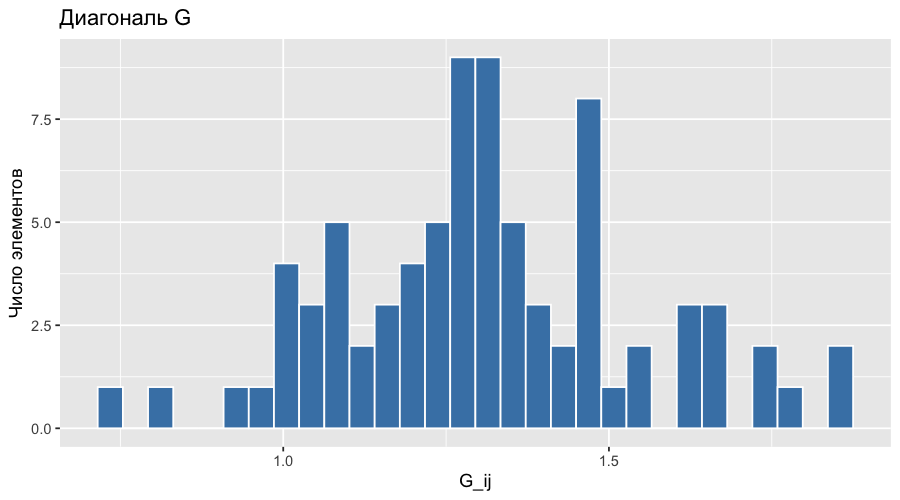

In [27]:
ggplot(data.frame(value = diag(G)), aes(x = value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  labs(title = "Диагональ G", x = "G_ij", y = "Число элементов")


- А недиагональные элементы показывают, что почти у все животные абсолютно нетипичны.


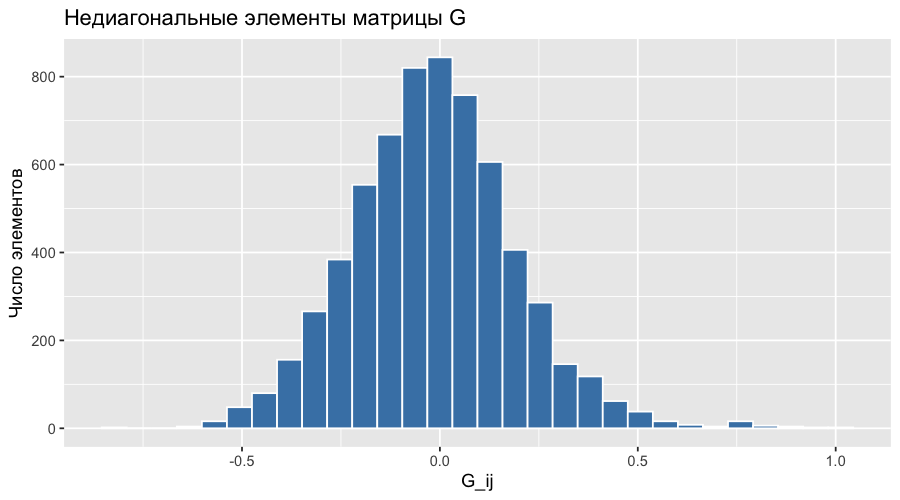

In [28]:
ggplot(data.frame(value = G[row(G) != col(G)]), aes(x = value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  labs(title = "Недиагональные элементы матрицы G", x = "G_ij", y = "Число элементов")


## 3.4. Построение матрицы A22

Следующую матрицу, которую нам необходимо будет построить - это матрица A22. Это подматрица A, вырезанная по индексам генотипированных особей. У коэффициентов внутри матрицы расчёт схожий, что и у матрицы A. Матрица A22 нам необходима, чтобы для дальнейшего построения H-матрицы.


In [29]:
geno_ids <- rownames(G)
A22 <- A[geno_ids, geno_ids]


In [30]:
print(knitr::kable(A22[1:5, 1:5], booktabs=TRUE, caption='Матрица A22 (фрагмент)'))




Table: Матрица A22 (фрагмент)

|   | 27|     28| 29|     30| 31|
|:--|--:|------:|--:|------:|--:|
|27 |  1| 0.0000|  0| 0.0000|  0|
|28 |  0| 1.0000|  0| 0.0625|  0|
|29 |  0| 0.0000|  1| 0.0000|  0|
|30 |  0| 0.0625|  0| 1.0000|  0|
|31 |  0| 0.0000|  0| 0.0000|  1|


## 3.5. Построение матрицы H

Следующую важную матрицу, которую нам необходимо будет вывести - это будет матрица H.
Н - это объединённая матрица родства, которая совмещает геномную матрицу G для генотипированных животных и матрицу А для животных из родословной. Она использует геномную матрицу G для генотипированных животных и матрицу родословной A для всех остальных. 

Алгоритм построения матрицы G:

1. Высчитываем delta - разность между фактическим родстом по SNP (матрица G) и ожидаемым родством (матрица A22). Delta отражает, насколько реальная генетика по SNP отличается от теоретического ожидания по родословной;


In [31]:
delta <- G - A22


In [32]:
print(knitr::kable(delta[1:5, 1:5], booktabs=TRUE, caption='Матрица delta (фрагмент)'))




Table: Матрица delta (фрагмент)

|   |         27|         28|         29|         30|         31|
|:--|----------:|----------:|----------:|----------:|----------:|
|27 |  0.0974934| -0.1895713| -0.0701936| -0.0093190| -0.0053661|
|28 | -0.1895713|  0.1797137| -0.0923299| -0.0307088| -0.0275023|
|29 | -0.0701936| -0.0923299|  0.3552225| -0.3548025|  0.0286289|
|30 | -0.0093190| -0.0307088| -0.3548025|  0.2239862| -0.2267285|
|31 | -0.0053661| -0.0275023|  0.0286289| -0.2267285|  0.4848777|


2. Начинаем создавать матрицу H на базе матрицы родословной A;

3. В созданной матрице H мы заменяем блок матрицы A22 на G ;


In [33]:
H <- A
H[geno_ids, geno_ids] <- A22 + delta


In [34]:
print(knitr::kable(H[1:5, 1:5], booktabs=TRUE, caption='Матрица H (фрагмент)'))




Table: Матрица H (фрагмент)

|    |  2| 113| 125| 136| 147|
|:---|--:|---:|---:|---:|---:|
|2   |  1|   0|   0|   0|   0|
|113 |  0|   1|   0|   0|   0|
|125 |  0|   0|   1|   0|   0|
|136 |  0|   0|   0|   1|   0|
|147 |  0|   0|   0|   0|   1|


4. В инвертированную матрицу H<sup>-1</sup> мы добавляем диагональную регуляризацию в зависиости от диагонального коэффициента. 
Регуляризация диагонали проходит согласно формуле: 1 / (диагональный элемент H + диагональный коэффициент).


In [35]:
H_inv <- solve(H + diag(diagonal_coefficient, nrow(H)))


In [36]:
print(knitr::kable(H_inv[1:5, 1:5], booktabs=TRUE, caption='Инвертированная матрица H (фрагмент)'))




Table: Инвертированная матрица H (фрагмент)

|    |          2|        113|        125|        136|        147|
|:---|----------:|----------:|----------:|----------:|----------:|
|2   |  1.0122064| -0.2974859|  0.0034969| -0.0009659| -0.1374728|
|113 | -0.2974859|  1.7465165| -0.3894190| -0.0012964|  0.0516849|
|125 |  0.0034969| -0.3894190|  1.8867892|  0.0014742| -0.4807928|
|136 | -0.0009659| -0.0012964|  0.0014742|  1.2306641| -0.0009743|
|147 | -0.1374728|  0.0516849| -0.4807928| -0.0009743|  1.6924888|


Теперь, когда все матрицы полносью посчитаны, можно производить расчёт оценки племенной ценности

## 3.6. Построение Z матрицы случайных эффектов

Если мы добавили в наши данные случайный эффект (т.е. тот эффект, который нам необходимо учитывать исключительно вместе с животным), нам необходимо построить Z матрицу случайного эффекта. Это будет последняя матрица, которую нам необходимо будет построить. Важно, что библиотека **rrBLUP** принимает только один случайный эффект. Само строение Z-матрицы cхоже с матрицей X с тем исключением, что мы используем здесь только один эффект, который автоматически обрабатывается в зависимости от его типа. Для того, чтобы была возможность обработки нескольких случайных эффектов, надо провести некоторые преобразования:


In [37]:
if (is_random == TRUE) {
  
  Z1 <- model.matrix(~ 0 + as.factor(animal), data=phenotypes_bl)
  Z2 <- model.matrix(~ 0 + economy, data=phenotypes_bl)
  Z <- cbind(Z1, Z2)
  
  n <- ncol(Z1)
  n_1 <- ncol(Z2)

  colnames(Z1) <- sub(".*\\)", "", colnames(Z1))
  H_inv_sync <- H_inv[colnames(Z1), colnames(Z1)]
  H_sync <- H[colnames(Z1), colnames(Z1)]
  
  K <- as.matrix(bdiag(H_sync, diag(ncol(Z2))))
  K <- (K + t(K)) / 2
  ev <- eigen(K, symmetric = TRUE)
  ev$values[ev$values < 1e-8] <- 1e-8
  K <- ev$vectors %*% diag(ev$values) %*% t(ev$vectors)
  
}


- Мы строим столько Z-матриц, сколько у нас есть случайных эффектов;


In [38]:
print(knitr::kable(Z1[1:5, 1:5], booktabs=TRUE, caption='Матрица Z1 (фрагмент)'))
print(knitr::kable(Z2[1:5, 1:2], booktabs=TRUE, caption='Матрица Z2 (фрагмент)'))




Table: Матрица Z1 (фрагмент)

|  2|  3|  4|  5|  6|
|--:|--:|--:|--:|--:|
|  1|  0|  0|  0|  0|
|  0|  0|  0|  0|  0|
|  0|  0|  0|  0|  0|
|  0|  0|  0|  0|  0|
|  0|  0|  0|  0|  0|




Table: Матрица Z2 (фрагмент)

| economyfarm1| economyfarm2|
|------------:|------------:|
|            0|            0|
|            0|            0|
|            0|            1|
|            0|            1|
|            0|            1|


- Мы объединяем получившиеся Z-матрицы по столбцам;


In [39]:
print(knitr::kable(Z[1:5, 1:5], booktabs=TRUE, caption='Матрица Z (фрагмент)'))




Table: Матрица Z (фрагмент)

| as.factor(animal)2| as.factor(animal)3| as.factor(animal)4| as.factor(animal)5| as.factor(animal)6|
|------------------:|------------------:|------------------:|------------------:|------------------:|
|                  1|                  0|                  0|                  0|                  0|
|                  0|                  0|                  0|                  0|                  0|
|                  0|                  0|                  0|                  0|                  0|
|                  0|                  0|                  0|                  0|                  0|
|                  0|                  0|                  0|                  0|                  0|


- Синхронизируем полученную Z-матрицу с инвертированной матрицей H<sup>-1</sup>;


- Строим K матрицу


In [40]:
print(knitr::kable(H_inv_sync[1:5, 1:5], booktabs=TRUE, caption='Синхронизированная и инвертированная матрица H (фрагмент)'))
print(K[1:5, 1:5])




Table: Синхронизированная и инвертированная матрица H (фрагмент)

|   |         2|          3|          4|          5|          6|
|:--|---------:|----------:|----------:|----------:|----------:|
|2  | 1.0122064|  0.4333881|  0.0533275|  0.0023013|  0.2662761|
|3  | 0.4333881| -0.0372493| -0.9094500|  0.0167326| -0.9685457|
|4  | 0.0533275| -0.9094500|  2.0517126| -0.0078635| -0.2651114|
|5  | 0.0023013|  0.0167326| -0.0078635|  1.5587690| -0.0097923|
|6  | 0.2662761| -0.9685457| -0.2651114| -0.0097923|  0.3532520|


            [,1]        [,2]        [,3]        [,4]        [,5]
[1,] 1.014842461 0.012894497 0.006412792 0.001411455 0.016891854
[2,] 0.012894497 1.088140137 0.013249383 0.002591212 0.010546800
[3,] 0.006412792 0.013249383 1.027207050 0.064297059 0.005325120
[4,] 0.001411455 0.002591212 0.064297059 1.000962470 0.001003055
[5,] 0.016891854 0.010546800 0.005325120 0.001003055 1.058363326


Теперь, когда все матрицы полносью посчитаны, можно производить расчёт оценки племенной ценности

# 4. Расчёт оценки племенной ценности у животных
Расчёт оценки племенной ценности мы будем производить с помощью функции mixed.solved из библиотеки rrBLUP. 

Для расчёта оценки мы берём:

- в случае отсутствия случайного эффекта: значение трейта из данных фенотипов, матрица Х, инвертированная матрица H;

- в случае наличия случайного эффекта: значение трейта из данных фенотипов, матрица Х, матрица Z;


In [41]:
if (is_random == FALSE) {
  res <- mixed.solve(y=phenotypes_bl$trait, 
                   X=X, 
                   K=H_inv)
  names(res$u) <- common_levels[as.numeric(names(res$u))]
  EBV <- res$u
} else {
  res <- mixed.solve(y=phenotypes_bl$trait, 
                   X=X,
                   Z=Z,
                   K=K)
  EBV <- res$u[1:n]
  EBV1 <- res$u[(n + 1):length(res$u)]
  
  names(EBV) <- colnames(Z1)
  names(EBV) <- common_levels[as.numeric(names(EBV))]
  names(EBV1) <- colnames(Z2)
}


Мы получаем оценки племенной ценности у животных. Теперь посмотрим на их распределение


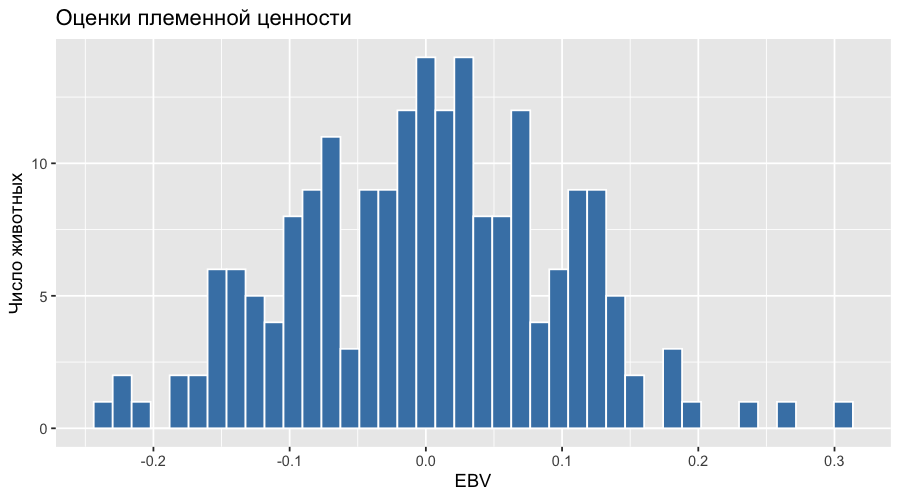

In [42]:
ggplot(data.frame(value = as.numeric(EBV)), aes(x = value)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Оценки племенной ценности", x = "EBV", y = "Число животных")


# 5. Проверка качества полученной оценки

После того как оценки посчитаны, нам необходимо оценить качество проделанной работы. Проверка качества является неотъемлемой частью любого анализа, и здесь она будет состоять из нескольких частей:

- расчёт стандартной ошибки;

- расчёт точности;

- расчёт корреляции оценки с данными трейта;

## 5.1. Расчёт стандартной ощибки среднего

Стандартная ошибка среднего


In [43]:
SE <- sqrt(res$Vu * diag(H_inv))
names(SE) <- common_levels[as.numeric(names(SE))]


NaNs produced


Removed 32 rows containing non-finite outside the scale range (`stat_bin()`).


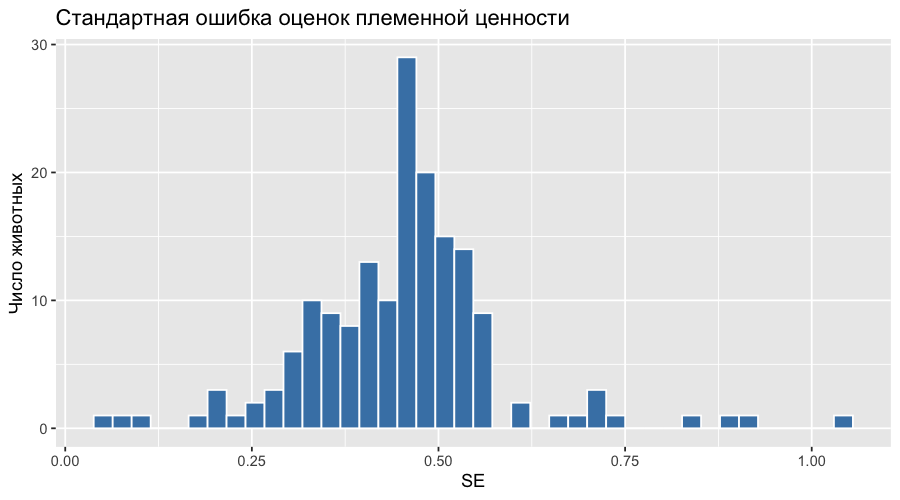

In [44]:
ggplot(data.frame(value = as.numeric(SE)), aes(x = value)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Стандартная ошибка оценок племенной ценности", x = "SE", y = "Число животных")


In [45]:
solutions <- as.data.frame(cbind(EBV, SE))


## 5.2. Расчёт точности


In [46]:
solutions$rel <- 1 - ((solutions$SE ** 2) / res$Vu)


Removed 32 rows containing non-finite outside the scale range (`stat_bin()`).


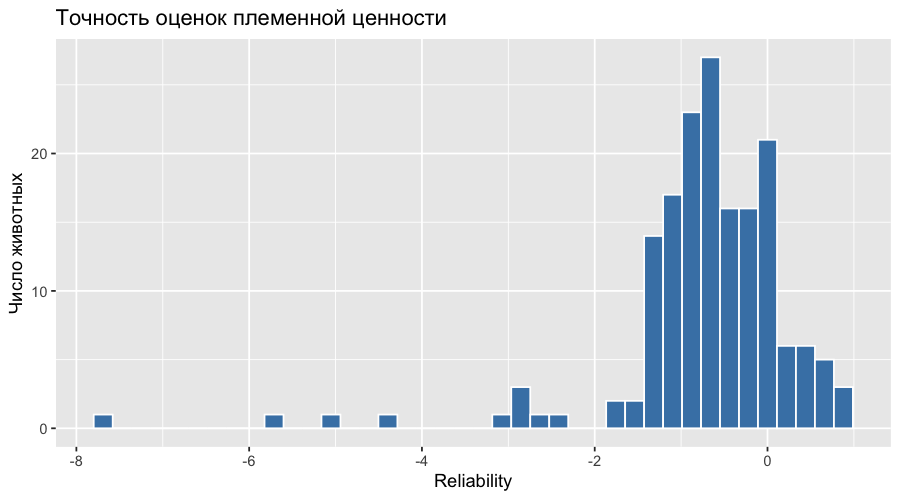

In [47]:
ggplot(solutions, aes(x = rel)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Точность оценок племенной ценности", x = "Reliability", y = "Число животных")


## 5.3. Расчёт корреляции оценки с данными трейта

Расчёт корреляции нам позволит увидеть зависимость между оценкой и трейтом в данных.


In [48]:
cor(phenotypes$trait, solutions$EBV)


[1] -0.02427156




Table: EBV животных (фрагмент)

|    |    EBV|    SE|    rel|
|:---|------:|-----:|------:|
|1   |  0.121| 0.361| -0.012|
|10  |  0.026| 0.474| -0.747|
|100 |  0.134| 0.493| -0.887|
|101 |  0.048| 0.398| -0.231|
|102 | -0.151| 0.467| -0.692|
|103 | -0.041| 0.544| -1.299|
|104 | -0.231| 0.397| -0.224|
|105 |  0.045| 0.398| -0.232|




Table: Случайный эффект хозяйства

|farm         | effect|
|:------------|------:|
|economyfarm1 | -0.258|
|economyfarm2 | -0.026|
|economyfarm3 | -0.271|
|economyfarm4 |  0.554|


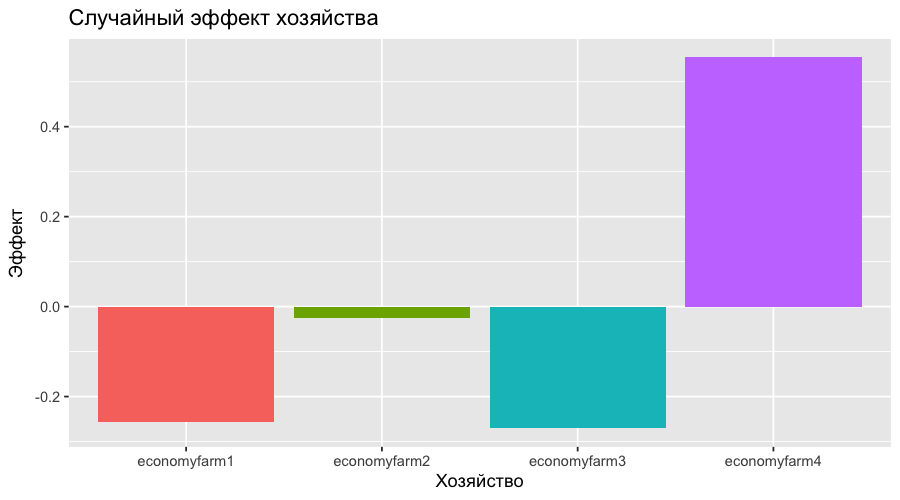

In [49]:
print(knitr::kable(head(solutions, 8), digits = 3, caption = 'EBV животных (фрагмент)'))
farm_eff <- data.frame(farm = names(EBV1), effect = as.numeric(EBV1))
print(knitr::kable(farm_eff, digits = 3, caption = 'Случайный эффект хозяйства'))
ggplot(farm_eff, aes(x = farm, y = effect, fill = farm)) +
  geom_col() +
  labs(title = 'Случайный эффект хозяйства', x = 'Хозяйство', y = 'Эффект') +
  theme(legend.position = 'none')


# 6. Заключение

В модель ssGBLUP добавлен случайный эффект хозяйства. EBV животных считаются на фоне фермы: блочная матрица K склеивает родство животных и независимые эффекты `economy`. Полученные оценки можно использовать для отбора внутри хозяйства, не смешивая генетический эффект с фоном фермы.
